# 19 — Preparación del modelo: EDA, limpieza y conversión
Hasta el notebook 18 el proyecto es **descriptivo**: mide la congestión, no la predice. Desde aquí se agrega un **modelo
supervisado** siguiendo el orden pedido para el informe: **1. preprocesamiento** (este notebook) → **2. modelo** (20) →
**3. evaluación** (21) → **4. despliegue** (22).

**La pregunta.** Con lo que se sabe al empezar el año (cuántas causas se heredan, cuántas entran, de qué materia, en qué
territorio, con cuántos juzgados y cuánto personal), ¿se puede anticipar si un proceso va a **acumular mora**, es decir,
si su stock de causas pendientes va a **crecer**?

- **Unidad:** un tipo de proceso no penal en un territorio y una materia (por ejemplo, «divorcio, familia, Sucre capital»).
  Las materias penales quedan fuera porque el Anuario no publica sus causas resueltas, y sin ellas no hay objetivo.
- **Objetivo:** `flag_acumula_mora` = 1 si se resolvieron **menos causas de las que ingresaron** (`resueltas < ingresos_totales`,
  es decir, tasa de resolución < 1; notebook 10). Como `pendientes_fin = stock heredado + ingresos − resueltas`, ese año
  el stock crece.
- Es un problema de **clasificación binaria**.

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/modelado.ipynb
from scipy import stats

datos = cargar_conjunto()
y = datos[OBJETIVO]
print(len(datos), "filas;", len(ORIGINALES), "variables originales;", len(INGENIERIA), "nuevas;", len(COMPLETA), "en total")
print("acumulan mora:", int(y.sum()), f"({y.mean():.1%});", "no acumulan:", int((1 - y).sum()))

1240 filas; 19 variables originales; 8 nuevas; 27 en total
acumulan mora: 608 (49.0%); no acumulan: 632


## Controles del conjunto
- Las filas son los procesos **con movimiento** (tipo de elemento `proceso` y al menos una causa atendida). No se filtra
  por la tasa de congestión, aunque sería lo más cómodo: esa tasa se divide por las resueltas y no existe cuando no se
  resolvió nada. Quitar esas filas sería **elegir los ejemplos mirando la respuesta** (casi todos acumulan mora) y el
  modelo aprendería con un conjunto más fácil que el real.
- El objetivo se puede reconstruir: acumula mora exactamente cuando las resueltas son menos que los ingresos del año.
- Ninguna columna excluida por fuga entra al modelo, y las clases están balanceadas (ninguna pasa del 60 %).

In [2]:
curado = pd.read_parquet(CURATED / "features" / "dataset_analitico_curado.parquet")
filas = curado[(curado["tipo_elemento_analitico"] == "proceso") & (curado["atendidas"] > 0)]
assert len(filas) == len(datos) == 1240
sin_tasa = int(filas["tasa_congestion"].isna().sum())
print(sin_tasa, "procesos sin tasa de congestión (cero resueltas) quedan dentro;",
      "de ellos acumulan mora:", int(datos.loc[filas["tasa_congestion"].isna().to_numpy(), OBJETIVO].sum()))
reconstruido = (filas["resueltas"].astype(float) < filas["ingresos_totales"]).astype(int).to_numpy()
assert (reconstruido == datos[OBJETIVO].to_numpy()).all(), "el objetivo no coincide con su definición"
assert not set(FUGA) & set(COMPLETA), "una variable con fuga se coló en el modelo"
assert set(FUGA) <= set(curado.columns), "una columna de la lista de fuga no existe"
assert 0.4 < y.mean() < 0.6
assert len(set(COMPLETA)) == len(COMPLETA)
print("controles OK")

118 procesos sin tasa de congestión (cero resueltas) quedan dentro; de ellos acumulan mora: 67
controles OK


## 1.1 EDA: cómo se ve el objetivo
Primero, cuánto cambia la proporción de procesos que acumulan mora según la materia y el ámbito. Si fuera igual en
todas partes, esas variables no servirían para predecir.

In [3]:
resumen_materia = (datos.groupby("materia_homologada")[OBJETIVO].agg(filas="size", acumulan="sum", proporcion="mean")
                   .sort_values("proporcion", ascending=False))
resumen_ambito = datos.groupby("ambito")[OBJETIVO].agg(filas="size", acumulan="sum", proporcion="mean")
display(resumen_materia.round(3))
display(resumen_ambito.round(3))

,filas,acumulan,proporcion
materia_homologada,,,
Público Civil y Comercial,384,221,0.576
Público de Familia,349,163,0.467
Público Niñez y Adolescencia,325,151,0.465
Partido de Trabajo y Seguridad Social,152,61,0.401
Partido Administrativo Coactivo Fiscal y Tributario,30,12,0.400


,filas,acumulan,proporcion
ambito,,,
capital,711,343,0.482
provincia,529,265,0.501


Ahora cada variable numérica frente al objetivo. Se usa la **correlación de Spearman** (por rangos), porque las
cantidades de causas son muy asimétricas y un proceso enorme no debe dominar la medida.

In [4]:
numericas = [c for c in COMPLETA if c not in CATEGORICAS]
filas_corr = []
for c in numericas:
    rho, p = stats.spearmanr(datos[c], y, nan_policy="omit")
    filas_corr.append({"variable": c, "nombre": NOMBRES[c], "grupo": "original" if c in ORIGINALES else "ingeniería",
                       "spearman": rho, "p_valor": p, "asimetria": stats.skew(datos[c].dropna())})
corr = pd.DataFrame(filas_corr).sort_values("spearman", key=abs, ascending=False)
corr.to_csv(MODELO_DIR / "eda_correlaciones.csv", index=False)
display(corr.round(3))

,variable,nombre,grupo,spearman,p_valor,asimetria
5,ingresos_totales,ingresos del año,original,0.240,0.000,6.097
17,log_ingresos,log de los ingresos,ingeniería,0.240,0.000,0.457
1,nuevas_ingresadas,causas nuevas,original,0.236,0.000,5.882
18,presion_stock,presión del stock,ingeniería,-0.232,0.000,12.353
19,ingresos_por_juzgado,ingresos por juzgado,ingeniería,0.204,0.000,4.398
6,atendidas,causas atendidas,original,0.167,0.000,5.645
3,preliminares_formalizados,preliminares formalizados,original,0.098,0.001,11.989
7,num_juzgados_pagina,juzgados (materia y territorio),original,0.077,0.006,0.646
22,prop_excusa,proporción por excusa,ingeniería,0.077,0.007,10.455
9,recurso_tribunales_publicados,tribunales del territorio,original,0.075,0.009,0.189


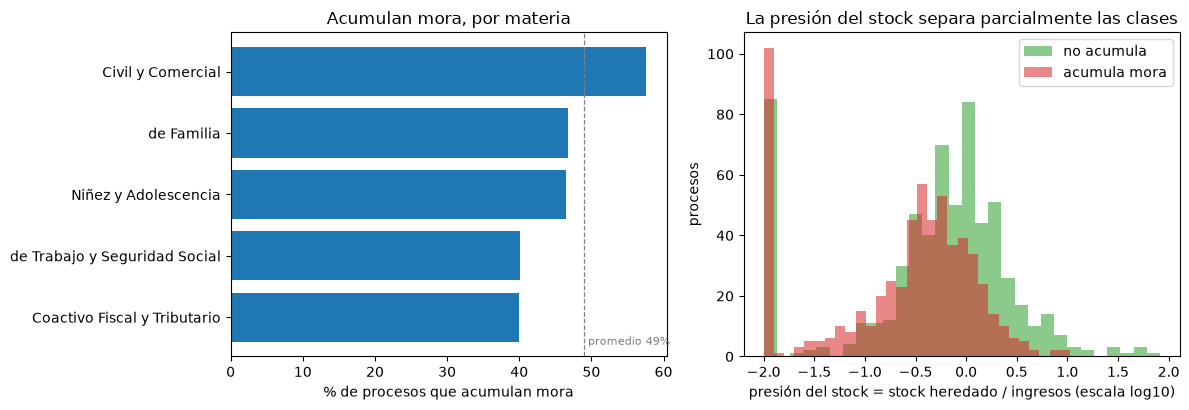

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = ejes[0]
etiquetas = [m.replace("Público ", "").replace("Partido ", "").replace("Administrativo ", "") for m in resumen_materia.index]
ax.barh(etiquetas[::-1], resumen_materia["proporcion"][::-1] * 100, color="tab:blue")
ax.axvline(y.mean() * 100, color="gray", ls="--", lw=0.9)
ax.text(y.mean() * 100 + 0.5, -0.45, f"promedio {y.mean():.0%}", fontsize=8, color="gray")
ax.set_xlabel("% de procesos que acumulan mora")
ax.set_title("Acumulan mora, por materia")
ax = ejes[1]
for clase, color, nombre in [(0, "tab:green", "no acumula"), (1, "tab:red", "acumula mora")]:
    v = datos.loc[y == clase, "presion_stock"]
    ax.hist(np.log10(v + 0.01), bins=30, alpha=0.55, color=color, label=nombre)
ax.set_xlabel("presión del stock = stock heredado / ingresos (escala log10)")
ax.set_ylabel("procesos")
ax.set_title("La presión del stock separa parcialmente las clases")
ax.legend()
plt.tight_layout()
guardar_figura(fig, "nb19_1.png")
plt.show()

## 1.2 Limpieza
**Fuga de información.** Es el error más grave al preparar un modelo: usar como pista algo que contiene la respuesta.
Aquí, el stock crece cuando se **resuelve** menos de lo que entra; cualquier columna calculada con las resueltas o con
el stock final le «dice» al modelo la respuesta. Se excluyen todas:

In [6]:
tabla_fuga = pd.DataFrame({"columna": list(FUGA), "motivo": list(FUGA.values())})
display(tabla_fuga)

,columna,motivo
0,resueltas,es parte de la respuesta: el stock crece cuand...
1,pendientes_fin,es el resultado del año (stock heredado + ingr...
2,tasa_resolucion,resueltas / ingresos
3,tasa_resolucion_con_readecuadas,usa resueltas
4,tasa_resolucion_solo_nuevas,usa resueltas
5,tasa_congestion,atendidas / resueltas
6,tasa_pendencia,usa pendientes al final
7,duracion_estimada_dias,usa resueltas y pendientes al final
8,acumulacion_neta_anual,es el objetivo en número (ingresos - resueltas)
9,flag_sin_resolucion_anual,usa resueltas


**Valores faltantes.** Dos formas de ingreso (preliminares y cautelares formalizados) solo existen en civil: en las otras
materias el faltante no es un dato perdido, es un **cero estructural**, y se llenó con 0 al cargar. Si se imputaran con la
mediana se inventarían causas que no existen. Lo que queda faltante se imputa con la **mediana del entrenamiento**
dentro del modelo (así la prueba no influye en el valor imputado).

In [7]:
faltantes = datos[COMPLETA].isna().sum()
faltantes = faltantes[faltantes > 0]
display(faltantes.rename("faltantes").to_frame())
assert faltantes.sum() < 0.01 * len(datos) * len(COMPLETA), "más faltantes de los esperados"
assert (datos["num_juzgados_pagina"] > 0).all(), "un proceso sin juzgados haría infinita la carga por juzgado"

,faltantes
recurso_tribunales_publicados,20


**Valores atípicos.** No se eliminan: un proceso con muchas causas es real (lo verificó el notebook 11 contra el PDF) y
es justamente donde importa acertar. En su lugar: los modelos de árboles (bagging, boosting) no se ven afectados por la
escala, y para los que sí (SVM, regresión logística) se agregan versiones en **logaritmo** y **cocientes**, que reducen la
asimetría.

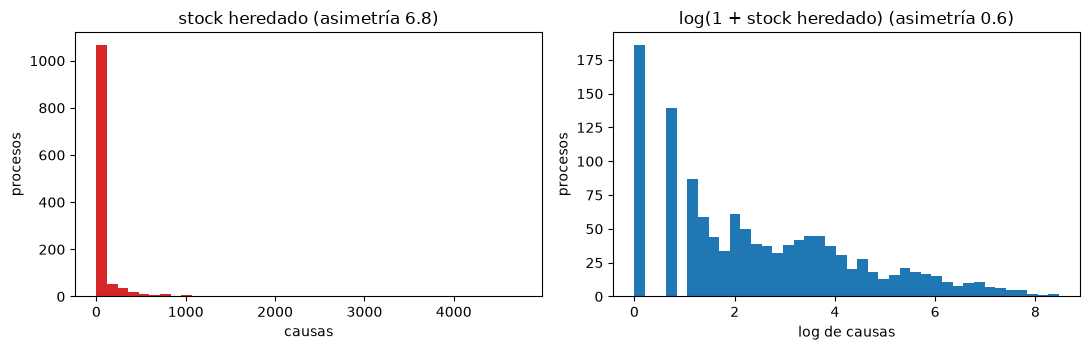

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].hist(datos["pendientes_inicio_efectivo"], bins=40, color="tab:red")
ejes[0].set_title(f"stock heredado (asimetría {stats.skew(datos['pendientes_inicio_efectivo']):.1f})")
ejes[0].set_xlabel("causas")
ejes[1].hist(datos["log_stock_inicial"], bins=40, color="tab:blue")
ejes[1].set_title(f"log(1 + stock heredado) (asimetría {stats.skew(datos['log_stock_inicial']):.1f})")
ejes[1].set_xlabel("log de causas")
for ax in ejes:
    ax.set_ylabel("procesos")
plt.tight_layout()
guardar_figura(fig, "nb19_2.png")
plt.show()

## 1.3 Conversión
| paso | qué hace | por qué |
|---|---|---|
| tipos | `Int64` con `<NA>` → `float64`; texto → `object` | scikit-learn no acepta el entero con nulos de pandas |
| ingeniería | 8 variables nuevas calculadas fila por fila | relaciones (cocientes, logs) que un modelo lineal o el SVM no construyen solos |
| one-hot | cada categoría → una columna 0/1 | el modelo necesita números; un código 1, 2, 3 inventaría un orden |
| escala | media 0 y desvío 1 (solo SVM, logística y stacking) | el SVM mide distancias: sin escala, la remuneración (millones) taparía todo lo demás |

Todos estos pasos viven **dentro de un `Pipeline`**: se ajustan con el entrenamiento y se aplican igual a la prueba.

In [9]:
tabla_ing = pd.DataFrame({"variable": INGENIERIA, "nombre": [NOMBRES[c] for c in INGENIERIA],
                          "formula": [FORMULAS[c] for c in INGENIERIA]})
display(tabla_ing)
pre = preprocesador(COMPLETA, escalar=True).fit(datos[COMPLETA])
matriz = pre.transform(datos[COMPLETA])
n_onehot = sum(datos[c].nunique() for c in CATEGORICAS)
print(f"{len(COMPLETA)} variables -> {matriz.shape[1]} columnas numéricas tras el one-hot "
      f"({len(COMPLETA) - len(CATEGORICAS)} numéricas + {n_onehot} de {len(CATEGORICAS)} categóricas)")
assert matriz.shape[1] == len(COMPLETA) - len(CATEGORICAS) + n_onehot
assert np.isfinite(matriz).all()

,variable,nombre,formula
0,log_stock_inicial,log del stock heredado,log(1 + stock heredado)
1,log_ingresos,log de los ingresos,log(1 + ingresos del año)
2,presion_stock,presión del stock,stock heredado / (ingresos del año + 1)
3,ingresos_por_juzgado,ingresos por juzgado,ingresos del año / juzgados
4,stock_por_juzgado,stock por juzgado,stock heredado / juzgados
5,prop_acefalias,proporción de vacantes,puestos vacantes / puestos totales
6,prop_excusa,proporción por excusa,recibidas por excusa / (ingresos del año + 1)
7,sin_stock_inicial,sin stock heredado,1 si no había stock heredado


27 variables -> 40 columnas numéricas tras el one-hot (24 numéricas + 16 de 3 categóricas)


## Partición entrenamiento / prueba
80 % para entrenar y ajustar (con validación cruzada de 5 pliegues), 20 % guardado para la evaluación final del
notebook 21. La partición es **estratificada**: las dos partes tienen la misma proporción de procesos que acumulan mora.

In [10]:
idx_tr, idx_te = particion(datos)
part = pd.Series("entrenamiento", index=datos.index)
part[idx_te] = "prueba"
pd.DataFrame({"fila": datos.index, "particion": part, "tipo_proceso": datos["tipo_proceso"],
              "territorio": datos["territorio"], OBJETIVO: y}).to_csv(MODELO_DIR / "particion.csv", index=False)
print(len(idx_tr), "entrenamiento;", len(idx_te), "prueba")
print("proporción que acumula:", round(y[idx_tr].mean(), 3), "vs", round(y[idx_te].mean(), 3))
assert abs(y[idx_tr].mean() - y[idx_te].mean()) < 0.01

992 entrenamiento; 248 prueba
proporción que acumula: 0.49 vs 0.492


## Diccionario de variables del modelo

In [11]:
filas_var = []
for c in COMPLETA:
    filas_var.append({
        "variable": c, "nombre": NOMBRES[c],
        "grupo": "original" if c in ORIGINALES else "ingeniería",
        "tipo": "categórica" if c in CATEGORICAS else "numérica",
        "conversion": ("one-hot" if c in CATEGORICAS else
                       "cero estructural + imputación mediana + escala (SVM)" if c in CEROS_ESTRUCTURALES else
                       "imputación mediana + escala (SVM)"),
        "formula": FORMULAS.get(c, ""), "motivo_exclusion": "",
    })
for c, motivo in FUGA.items():
    filas_var.append({"variable": c, "nombre": c, "grupo": "excluida (fuga)", "tipo": "", "conversion": "",
                      "formula": "", "motivo_exclusion": motivo})
variables = pd.DataFrame(filas_var)
variables.to_csv(MODELO_DIR / "variables.csv", index=False)
variables["grupo"].value_counts()

grupo
original           19
excluida (fuga)    18
ingeniería          8
Name: count, dtype: int64

## Lectura
- **Se puede plantear como clasificación:** 1.240 procesos con movimiento, clases casi equilibradas (608 acumulan mora,
  49,0 %), así que la exactitud no engaña tanto como con clases desbalanceadas; aun así se reporta ROC-AUC y F1.
- **El filtro no mira la respuesta.** Se incluyen los 118 procesos que no resolvieron nada (sin tasa de congestión):
  67 de ellos acumulan mora. Si se hubieran quitado, el modelo aprendería con un conjunto más fácil que el real.
- **Ninguna variable sola decide.** Las correlaciones con el objetivo son débiles (|Spearman| ≤ 0,24). Los procesos con
  **más ingresos** tienden a acumular (+0,24), y los que heredan **mucho stock en relación con lo que entra** tienden a
  no acumular (presión del stock, −0,23): con muchas causas viejas en la mesa, el juzgado resuelve más de lo que recibe.
  El stock heredado solo, sin dividir por los ingresos, casi no dice nada (+0,04): la ingeniería aporta el cociente.
  Por eso tiene sentido un modelo que combine varias.
- **Civil acumula más** (58 % de sus procesos) que el resto (40 % a 47 %); capital y provincia casi no difieren (48 % y 50 %).
- **Limpieza:** 18 columnas fuera por fuga; un solo faltante real (tribunales del territorio, 20 filas, imputado con la
  mediana del entrenamiento); las cantidades tienen asimetría fuerte (ingresos 6,1) y el logaritmo la baja a 0,46.
- **19 variables originales + 8 de ingeniería = 27** (40 columnas tras el one-hot). Los números de la pizarra (19, 25, 5)
  eran ejemplos; aquí salen de los datos: 19 originales sin fuga, 27 con ingeniería y, en el notebook 21, las 5 más importantes.
- **Partición:** 992 procesos para entrenar y 248 para la prueba, con la misma proporción de la clase (49,0 % y 49,2 %).
